<a href="https://colab.research.google.com/github/Raleese/house-price-predictor/blob/main/house_price_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error

# Loading the dataset
housing = fetch_california_housing(as_frame = True)

X = housing.data
y = housing.target


# separate the test set (15%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

# Then separate validation from the remaining 85%
# 15% of the original dataset is 15/85 of the remaining data
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.15 / 0.85,
    random_state=42
)

# Create the linear regression model and train it
model = LinearRegression()
model.fit(X_train, y_train)

train_pred = model.predict(X_train)
valid_pred = model.predict(X_val)

# Training metrics evaluation
train_r2 = r2_score(y_train, train_pred)
train_rmse = root_mean_squared_error(y_train, train_pred)

# Validation metrics evaluation
valid_r2 = r2_score(y_val, valid_pred)
valid_rmse = root_mean_squared_error(y_val, valid_pred)

print(f"Training R^2: {train_r2:.3f}")
print(f"Training RMSE: {train_rmse:.3f}\n")

print(f"Validation R^2: {valid_r2:.3f}")
print(f"Validation RMSE: {valid_rmse:.3f}")


Training R^2: 0.608
Training RMSE: 0.724

Validation R^2: 0.615
Validation RMSE: 0.718


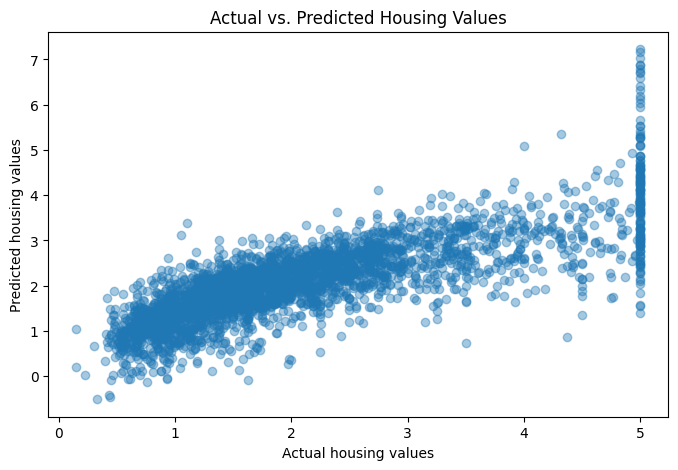

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(y_val, valid_pred, alpha=0.4)

plt.xlabel("Actual housing values")
plt.ylabel("Predicted housing values")
plt.title("Actual vs. Predicted Housing Values")

plt.show()